# Install

In [13]:
# Install dependencies
%pip install -q -U ultralytics pandas matplotlib


# Settings

In [10]:
from pathlib import Path
import json
import time

import pandas as pd
import torch
from IPython.display import display
from ultralytics import YOLO

DATA = "african-wildlife.yaml"
MODELS = {
    "YOLO26n": "yolo26n.pt",
    "YOLO11n": "yolo11n.pt",
    "YOLO8n": "yolov8n.pt",
}

EPOCHS = 100
IMGSZ = 640   # Resize 640x640
BATCH = 16    # 16 images per update
SEED = 42
DEVICE = 0 if torch.cuda.is_available() else "cpu"

Path("runs/african_wildlife").mkdir(parents=True, exist_ok=True)


# Training

In [4]:
# Train all models with identical settings
trained_models = {}
training_times = {}

for model_name, weights in MODELS.items():
    start_time = time.time()
    model = YOLO(weights)
    model.train(
        data=DATA,
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        device=DEVICE,
        seed=SEED,
        patience=20,  # Stop after 20 epochs without validation improvement
        project="runs/african_wildlife",
        name=model_name.lower(),
        exist_ok=True,
        pretrained=True,
        plots=True,
    )
    trained_models[model_name] = model
    training_times[model_name] = time.time() - start_time


Ultralytics 8.4.136 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=african-wildlife.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26n, nbs=64, nms=False, opset=None, 

# Evaluation

In [5]:
# Evaluate each model on the test split
comparison = []

for model_name, model in trained_models.items():
    weights_path = Path(model.trainer.save_dir) / "weights" / "best.pt"
    metrics = YOLO(str(weights_path)).val(
        data=DATA,
        split="test",
        imgsz=IMGSZ,
        batch=BATCH,
        device=DEVICE,
        plots=True,
    )
    comparison.append({
        "Model": model_name,
        "Precision": metrics.box.mp,
        "Recall": metrics.box.mr,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
        "mAP75": metrics.box.map75,
        "Training time (min)": training_times[model_name] / 60,
        "Best weights": str(weights_path),
    })

comparison_df = (
    pd.DataFrame(comparison)
    .sort_values("mAP50-95", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.style.format({
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
    "mAP50": "{:.4f}",
    "mAP50-95": "{:.4f}",
    "mAP75": "{:.4f}",
    "Training time (min)": "{:.2f}",
}))


Ultralytics 8.4.136 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 122 layers, 2,375,616 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2023.2±722.5 MB/s, size: 141.3 KB)
val: Scanning /content/datasets/african-wildlife/labels/test... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 2.2Kit/s 0.1s
val: New cache created: /content/datasets/african-wildlife/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 3.4it/s 4.4s
                   all        227        375      0.959      0.934      0.969      0.846
               buffalo         49         66      0.968      0.924      0.952      0.864
              elephant         58         99      0.935      0.939      0.974       0.81
                 rhino         55         75      0.986      0.951      0.991      0.914
                 zebra         66        135  

,Model,Precision,Recall,mAP50,mAP50-95,mAP75,Training time (min),Best weights
0,YOLO26n,0.9590,0.9342,0.9689,0.8463,0.9238,35.41,/content/runs/detect/runs/african_wildlife/yolo26n/weights/best.pt
1,YOLO11n,0.9793,0.9301,0.9803,0.8409,0.9345,33.66,/content/runs/detect/runs/african_wildlife/yolo11n/weights/best.pt
2,YOLO8n,0.9641,0.9454,0.9703,0.8279,0.9157,30.89,/content/runs/detect/runs/african_wildlife/yolo8n/weights/best.pt


In [6]:
# Save comparison results
comparison_df.to_csv("runs/african_wildlife/model_comparison.csv", index=False)
comparison_df.to_json("runs/african_wildlife/model_comparison.json", orient="records", indent=2)


## Metric guide and model-selection rule

**Metric Guide:**

| Metric        | What the metric is                      | What it tells us                                                                   |
|:--------------|:----------------------------------------|:-----------------------------------------------------------------------------------|
| Precision     | Correct predictions / all predictions   | Shows how often detections are correct; higher is better when false alarms matter. |
| Recall        | Correct detections / all real objects   | Shows how many animals are found; higher is better when missed animals matter.     |
| mAP50         | Average detection accuracy at IoU 0.50  | Broad detection quality; higher is better.                                         |
| mAP50-95      | Average mAP from IoU 0.50 to 0.95       | Primary overall metric; rewards accurate detections and tight boxes.               |
| mAP75         | Average detection accuracy at IoU 0.75  | Stricter box-localization quality; higher is better.                               |
| Training time | Minutes required to train               | Use only as a tie-breaker after accuracy and recall.                               |

**Best-model rule:** Choose the highest test mAP50-95. If scores are close, prefer higher recall for wildlife monitoring; prefer higher precision when false alarms are costly; use speed or model size as the final tie-breaker.

In [8]:
# Identify the best model by test mAP50-95
best_row = comparison_df.iloc[0]
print(f"Best model: {best_row['Model']}")
print(f"Weights: {best_row['Best weights']}")


Best model: YOLO26n
Weights: /content/runs/detect/runs/african_wildlife/yolo26n/weights/best.pt


<Axes: title={'center': 'African Wildlife Test-Set Model Comparison'}, xlabel='Model'>

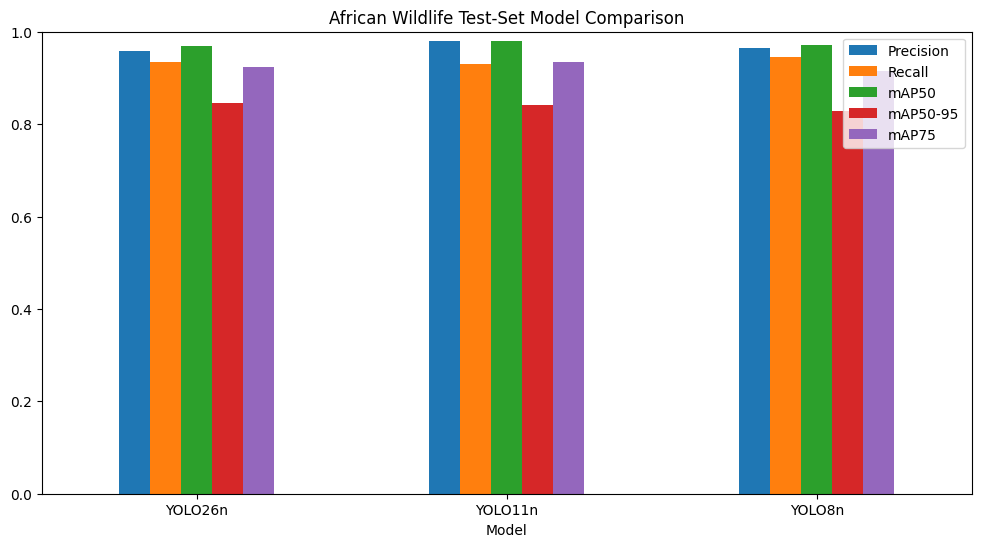

In [9]:
# Plot the main metrics
comparison_df.set_index("Model")[["Precision", "Recall", "mAP50", "mAP50-95", "mAP75"]].plot(
    kind="bar", figsize=(12, 6), ylim=(0, 1), rot=0,
    title="African Wildlife Test-Set Model Comparison"
)


In [12]:
from pathlib import Path
import shutil

weights_path = Path(model.trainer.save_dir) / "weights" / "best.pt"
output_path = Path("runs/african_wildlife") / f"{model_name.lower()}_best.pt"

shutil.copy2(weights_path, output_path)
print(f"{model_name} saved to: {output_path}")

YOLO8n saved to: runs/african_wildlife/yolo8n_best.pt


## Download Results

In [14]:
import shutil
from google.colab import files

# Define the directory to be zipped and the output zip file name
directory_to_zip = "/content/runs/detect/runs/african_wildlife"
output_zip_name = "african_wildlife_results"

# Create the zip archive
shutil.make_archive(output_zip_name, 'zip', directory_to_zip)

# Download the zip file
files.download(f"{output_zip_name}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>